# Barnacle Counter

Instead of scientists counting barnacles in photos by hand, which is time consuming and repetitive, my idea is to have the computer put a dot on each barnacle, so a person only has to check the dots and fix mistakes.

**Steps:**
1. Crop the photo to the inside of the wire frame
2. Get the real barnacle positions from the mask
3. Train a random forest to find barnacles
4. Score it
5. Test it on the unseen photo

**To run:** put `img1.png`, `mask1.png` and `unseen_img1.png` in the same folder as this notebook and run all cells. Needs opencv-python, numpy, matplotlib, scikit-learn.

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

## 1. Cropping to the frame

Only the barnacles inside the inner square of the frame are counted. The frame wire is a dark teal color, so I:
- convert to HSV and keep pixels with the wire's color
- use a closing to fill small gaps in the wire
- use connected components to find the region in the middle of the photo which is the inside of the square
- cut out the box around it

crop box (x, y, w, h): (1124, 464, 1427, 1474)


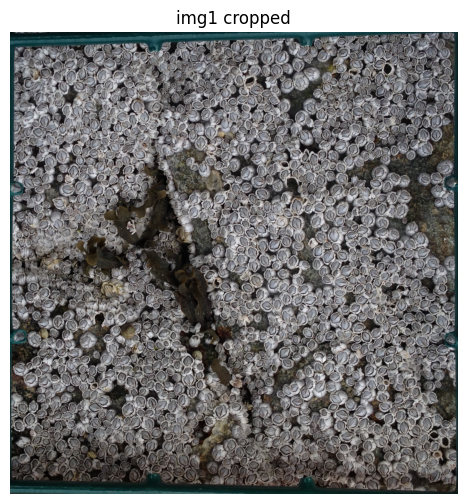

In [2]:
def crop_frame(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h = hsv[:, :, 0]
    s = hsv[:, :, 1]
    v = hsv[:, :, 2]

    # white wherever a pixel looks like the wire
    wire = (h > 80) & (h < 105) & (s > 120) & (v < 140)
    wire = wire.astype(np.uint8) * 255
    wire = cv2.morphologyEx(wire, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))

    # label the regions that are not wire, and take the one in the middle
    num, labels = cv2.connectedComponents(255 - wire)
    rows, cols = wire.shape
    middle = labels[int(rows * 0.45), int(cols * 0.5)]
    inside = (labels == middle).astype(np.uint8) * 255

    x, y, w, h = cv2.boundingRect(inside)
    return img[y:y + h, x:x + w], (x, y, w, h)


img1 = cv2.imread("img1.png")
crop1, box1 = crop_frame(img1)
print("crop box (x, y, w, h):", box1)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(crop1, cv2.COLOR_BGR2RGB))
plt.title("img1 cropped")
plt.axis("off")
plt.show()

## 2. Real barnacles from the mask

The mask is a see-through PNG where only the blue outlines are visible. When I drew the outlines on the photo, I noticed they go around the **grey part in the middle** of each barnacle, not the whole white shell. Those middles don't touch each other much, so each one can be counted as one blob.

Each outline can be one barnacle. Some outlines have small gaps, so I do a closing first so one barnacle doesn't get counted twice.

In [3]:
mask1 = cv2.imread("mask1.png", cv2.IMREAD_UNCHANGED)
outline = mask1[:, :, 3] > 0          # outlines are wherever the png isn't see-through

x, y, w, h = box1
outline = outline[y:y + h, x:x + w]   # cut the mask with the same box as the photo
outline = outline.astype(np.uint8) * 255
outline = cv2.morphologyEx(outline, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))

contours, _ = cv2.findContours(outline, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

answer = np.zeros(outline.shape, np.uint8)   # 1 = inside a barnacle outline
real = []                                     # barnacle centers
areas = []
for c in contours:
    area = cv2.contourArea(c)
    if area < 20:
        continue   # tiny specks
    cv2.drawContours(answer, [c], -1, 1, -1)   # fill it in
    M = cv2.moments(c)
    real.append((M["m10"] / M["m00"], M["m01"] / M["m00"]))
    areas.append(area)

real = np.array(real)
print("real barnacles:", len(real))

real barnacles: 1500


The photo is big, so I shrink everything to 1200 pixels wide to make the model faster.

image size: (1240, 1200, 3)  typical radius: 9.0 pixels


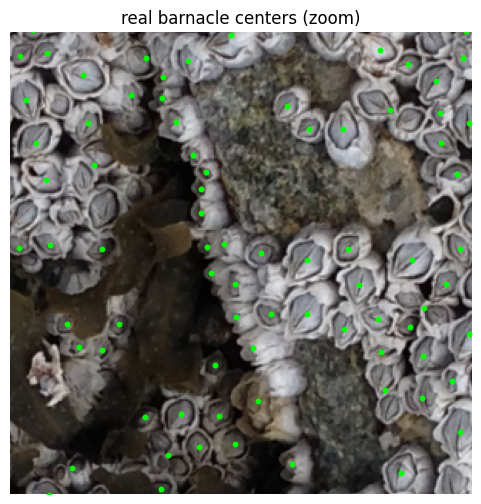

In [4]:
scale = 1200 / crop1.shape[1]
img = cv2.resize(crop1, None, fx=scale, fy=scale)
answer = cv2.resize(answer, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
real = real * scale
radius = np.sqrt(np.median(areas) * scale * scale / np.pi)   # typical barnacle middle as a circle
print("image size:", img.shape, " typical radius:", round(radius, 1), "pixels")

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.scatter(real[:, 0], real[:, 1], s=10, c="lime")
plt.xlim(300, 600)
plt.ylim(600, 300)
plt.title("real barnacle centers (zoom)")
plt.axis("off")
plt.show()

## 3. How I score it

A predicted dot is correct if it's within 1.5 radii of a real barnacle, and each real barnacle can only be matched once.
- **precision** = how many of my dots are real barnacles
- **recall** = how many real barnacles got a dot
- **count error** = how far off the total is

I also scored random dots to see what guessing gets, since barnacles are packed so tightly.

In [5]:
def score(found, real, max_dist):
    used = [False] * len(found)
    hits = 0
    for t in real:
        best = -1
        best_d = max_dist
        for j in range(len(found)):
            if used[j]:
                continue
            d = np.sqrt((t[0] - found[j][0]) ** 2 + (t[1] - found[j][1]) ** 2)
            if d < best_d:
                best_d = d
                best = j
        if best >= 0:
            used[best] = True
            hits += 1
    precision = hits / len(found)
    recall = hits / len(real)
    count_error = (len(found) - len(real)) / len(real)
    return precision, recall, count_error


max_dist = 1.5 * radius
rng = np.random.default_rng(0)
random_dots = np.column_stack([rng.uniform(0, img.shape[1], len(real)),
                               rng.uniform(0, img.shape[0], len(real))])
p, r, err = score(random_dots, real, max_dist)
print(f"random dots: precision {p:.2f}, recall {r:.2f}")

random dots: precision 0.42, recall 0.42


Random dots already get about 0.42 precision and recall, so the model has to do a lot better than that.

## 4. Random forest

Every pixel gets a few numbers (features):
- its color (blue, green, red) and gray brightness
- a small blur and a big blur (brightness of the area around it)
- edge strength from Sobel
- small blur minus big blur (is it lighter or darker than its surroundings)

In [6]:
def get_features(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
    b, g, r = cv2.split(img.astype(np.float32))
    blur_small = cv2.GaussianBlur(gray, (5, 5), 0)
    blur_big = cv2.GaussianBlur(gray, (21, 21), 0)
    gx = cv2.Sobel(blur_small, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(blur_small, cv2.CV_32F, 0, 1)
    edges = np.sqrt(gx ** 2 + gy ** 2)
    feats = np.dstack([b, g, r, gray, blur_small, blur_big, edges, blur_small - blur_big])
    return feats.reshape(-1, 8)   # one row per pixel


half = img.shape[1] // 2
train_img = img[:, :half]
train_ans = answer[:, :half]
test_img = img[:, half:]
test_real = real[real[:, 0] >= half] - [half, 0]   # shift x to match the cut image

# 30000 random pixels from the left half (using all of them is slow)
X = get_features(train_img)
y = train_ans.flatten()
pick = rng.choice(len(y), 30000, replace=False)

model = RandomForestClassifier(n_estimators=50, class_weight="balanced", random_state=0)
model.fit(X[pick], y[pick])
print("trained")

trained


To count: predict every pixel, use an opening to remove tiny specks, then connected components. Each blob = one barnacle. Blobs smaller than `min_area` are ignored as noise.

In [7]:
def find_barnacles(model, img, min_area):
    pred = model.predict(get_features(img))
    pred = pred.reshape(img.shape[0], img.shape[1]).astype(np.uint8)
    pred = cv2.morphologyEx(pred, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))

    num, labels, stats, centers = cv2.connectedComponentsWithStats(pred)
    found = []
    for i in range(1, num):
        if stats[i][4] >= min_area:
            found.append(centers[i])
    return np.array(found)


for min_area in [10, 20, 30, 40]:
    found = find_barnacles(model, test_img, min_area)
    p, r, err = score(found, test_real, max_dist)
    print(f"min_area {min_area}: found {len(found)}, real {len(test_real)}, "
          f"count error {err:+.0%}, precision {p:.2f}, recall {r:.2f}")

min_area 10: found 1181, real 759, count error +56%, precision 0.58, recall 0.90


min_area 20: found 925, real 759, count error +22%, precision 0.70, recall 0.86


min_area 30: found 790, real 759, count error +4%, precision 0.78, recall 0.81


min_area 40: found 708, real 759, count error -7%, precision 0.83, recall 0.77


min_area = 30 gives the best balance: the count is about 4% too high, and precision and recall are both around 0.8, way above the 0.42 from random dots. (I picked this by looking at the test half, so it's a bit optimistic.)

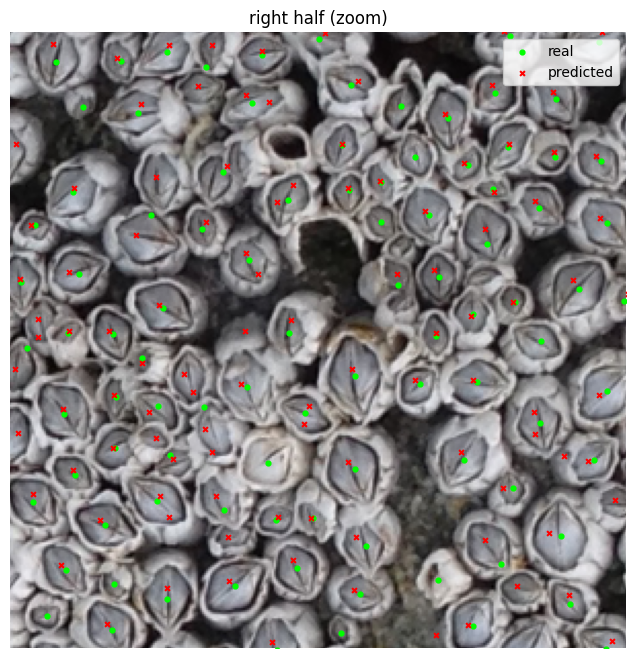

In [8]:
found = find_barnacles(model, test_img, 30)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB))
plt.scatter(test_real[:, 0], test_real[:, 1], s=12, c="lime", label="real")
plt.scatter(found[:, 0], found[:, 1], s=12, c="red", marker="x", label="predicted")
plt.xlim(0, 300)
plt.ylim(600, 300)
plt.legend()
plt.title("right half (zoom)")
plt.axis("off")
plt.show()

Most red crosses land on the grey middle of a barnacle. Some are on rock, and some barnacles are missed.

## 5. Unseen photo

There are no labels for this one, so I can only look at it. I train a new model on all of img1 first.

predicted barnacles: 788


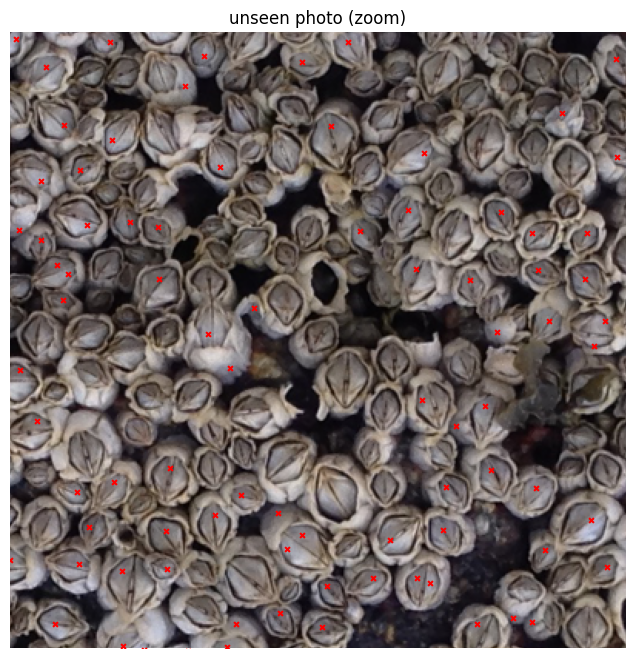

In [9]:
X = get_features(img)
y = answer.flatten()
pick = rng.choice(len(y), 30000, replace=False)
model_all = RandomForestClassifier(n_estimators=50, class_weight="balanced", random_state=0)
model_all.fit(X[pick], y[pick])

unseen = cv2.imread("unseen_img1.png")
crop_u, _ = crop_frame(unseen)
unseen_img = cv2.resize(crop_u, None, fx=1200 / crop_u.shape[1], fy=1200 / crop_u.shape[1])

found_u = find_barnacles(model_all, unseen_img, 30)
print("predicted barnacles:", len(found_u))

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(unseen_img, cv2.COLOR_BGR2RGB))
plt.scatter(found_u[:, 0], found_u[:, 1], s=12, c="red", marker="x")
plt.xlim(300, 700)
plt.ylim(800, 400)
plt.title("unseen photo (zoom)")
plt.axis("off")
plt.show()

A lot of barnacles have no dot. The unseen photo is darker and more yellow than img1, and the model only learned img1's colors.

To fix this I tried histogram matching (from my image processing class): change the unseen photo's colors so each channel's histogram matches img1's.

before: 788  after histogram matching: 1255


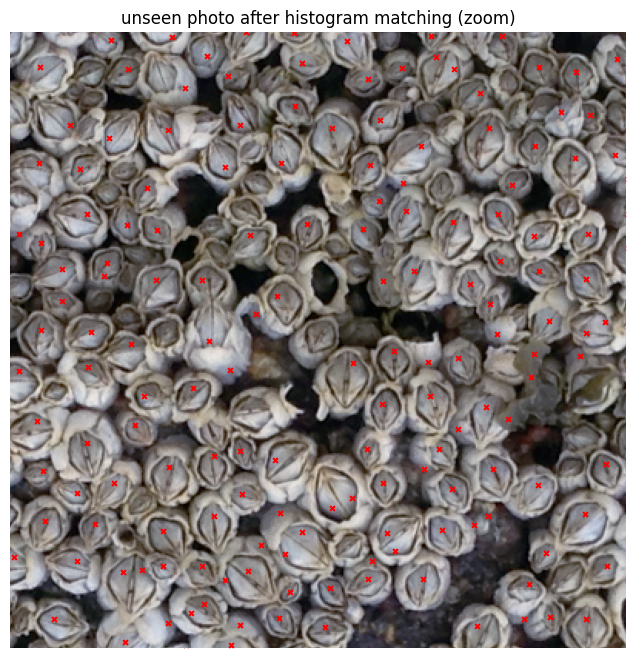

In [10]:
def match_histogram(src, ref):
    out = np.zeros_like(src)
    for ch in range(3):
        s_vals, s_counts = np.unique(src[:, :, ch], return_counts=True)
        r_vals, r_counts = np.unique(ref[:, :, ch], return_counts=True)
        s_cdf = np.cumsum(s_counts) / src[:, :, ch].size
        r_cdf = np.cumsum(r_counts) / ref[:, :, ch].size
        lut = np.zeros(256)
        lut[s_vals] = np.interp(s_cdf, r_cdf, r_vals)   # map each level to the ref level with the same cdf
        out[:, :, ch] = lut[src[:, :, ch]].astype(np.uint8)
    return out


unseen_fixed = match_histogram(unseen_img, img)
found_fixed = find_barnacles(model_all, unseen_fixed, 30)
print("before:", len(found_u), " after histogram matching:", len(found_fixed))

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(unseen_fixed, cv2.COLOR_BGR2RGB))
plt.scatter(found_fixed[:, 0], found_fixed[:, 1], s=12, c="red", marker="x")
plt.xlim(300, 700)
plt.ylim(800, 400)
plt.title("unseen photo after histogram matching (zoom)")
plt.axis("off")
plt.show()

After matching, most barnacles get a dot, but a few get two dots. I can't measure how accurate this is without labels.

## 6. Results and conclusions

| | count error | precision | recall |
|---|---|---|---|
| random dots | | 0.42 | 0.42 |
| random forest (right half of img1) | +4% | 0.78 | 0.81 |

Unseen photo: 788 barnacles before histogram matching, 1255 after.

**Problems:**

- The mask doesn't label every barnacle, so some of my "wrong" dots are actually real barnacles.
- The crop only works if the frame is near the middle of the photo.

**Conclusions:**
The model does much better than random guessing on img1 (precision and recall about 0.8 vs 0.42), but it still makes mistakes and struggles with different lighting, as the unseen photo showed.